## Grid Search Hyperparameter optimization

This case study is all about using grid searches to identify the optimal parameters for a machine learning algorithm. To complere this case study, you'll use the Pima Indian diabetes dataset from Kaggle and KNN. Follow along with the preprocessing steps of this case study.

Load the necessary packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

# Import machine learning tools
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Set random seed to try make this exercise and solutions reproducible
# (NB: this is just for teaching purpose and not something you would do in real life)
random_seed_number = 42
np.random.seed(random_seed_number)

#### Load the diabetes data

In [2]:
diabetes_data = pd.read_csv('data/diabetes.csv')
diabetes_data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


**<font color='teal'> Start by reviewing the data info.</font>**

In [3]:
# Display dataset information, including column names, data types, and non-null counts
diabetes_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


**<font color='teal'> Apply the describe function to the data.</font>**

In [4]:
# Display descriptive statistics for each numerical column
diabetes_data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


**<font color='teal'> Currently, the missing values in the dataset are represented as zeros. Replace the zero values in the following columns ['Glucose','BloodPressure','SkinThickness','Insulin','BMI'] with nan .</font>**

In [5]:
# Replace zero values with NaN in columns where zero represents missing data
columns_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

diabetes_data[columns_with_zeros] = diabetes_data[columns_with_zeros].replace(0, np.nan)

# Check the number of missing values in each column
diabetes_data.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

**<font color='teal'> Plot histograms of each column. </font>**

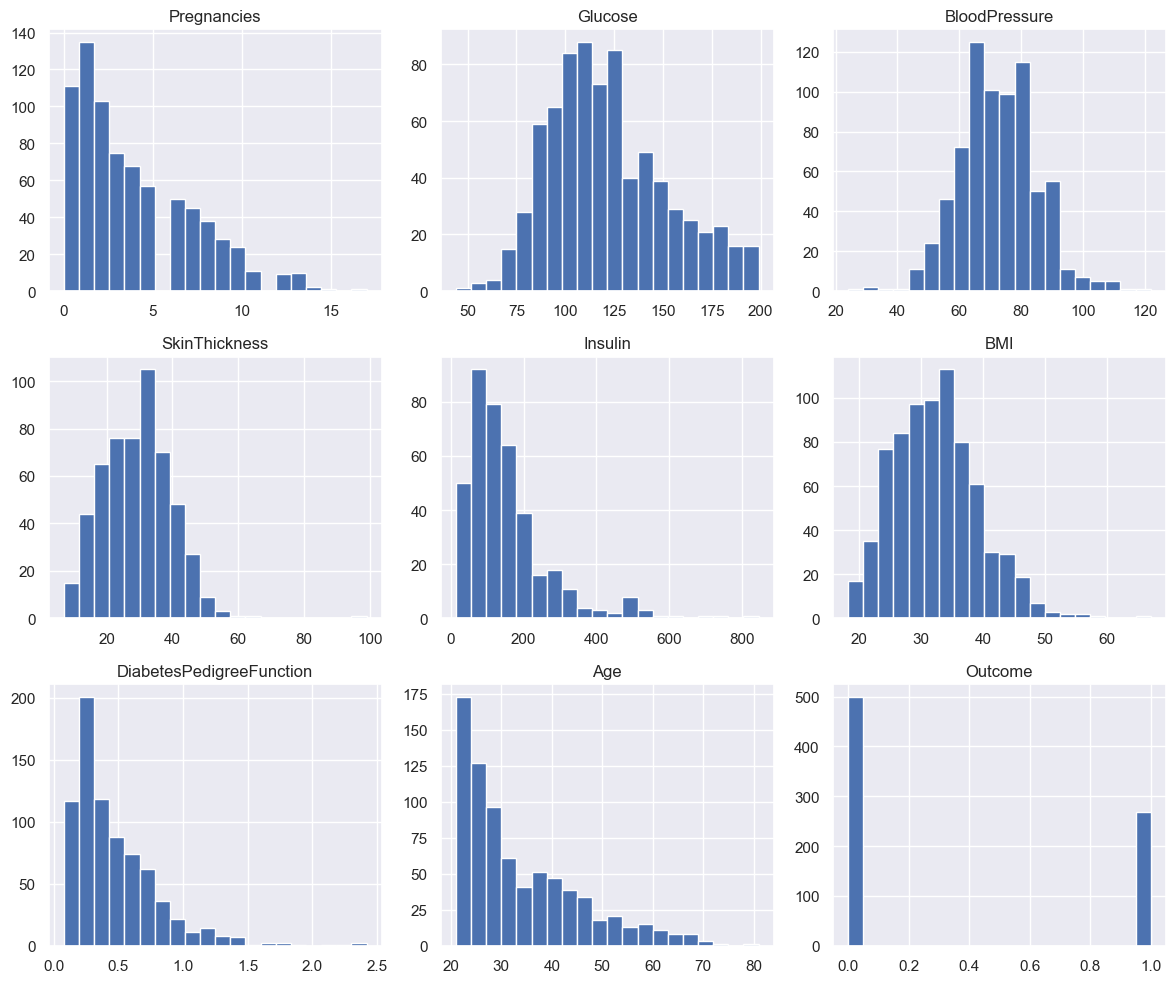

In [6]:
# Plot histograms to examine the distribution of each column
diabetes_data.hist(figsize=(12, 10), bins=20)

plt.tight_layout()
plt.show()

#### Replace the zeros with mean and median values.

In [7]:
# Replace missing values with the mean for Glucose and BloodPressure
diabetes_data['Glucose'] = diabetes_data['Glucose'].fillna(
    diabetes_data['Glucose'].mean()
)

diabetes_data['BloodPressure'] = diabetes_data['BloodPressure'].fillna(
    diabetes_data['BloodPressure'].mean()
)

# Replace missing values with the median for SkinThickness, Insulin, and BMI
diabetes_data['SkinThickness'] = diabetes_data['SkinThickness'].fillna(
    diabetes_data['SkinThickness'].median()
)

diabetes_data['Insulin'] = diabetes_data['Insulin'].fillna(
    diabetes_data['Insulin'].median()
)

diabetes_data['BMI'] = diabetes_data['BMI'].fillna(
    diabetes_data['BMI'].median()
)

# Check that all missing values have been replaced
diabetes_data.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

**<font color='teal'> Plot histograms of each column after replacing nan. </font>**

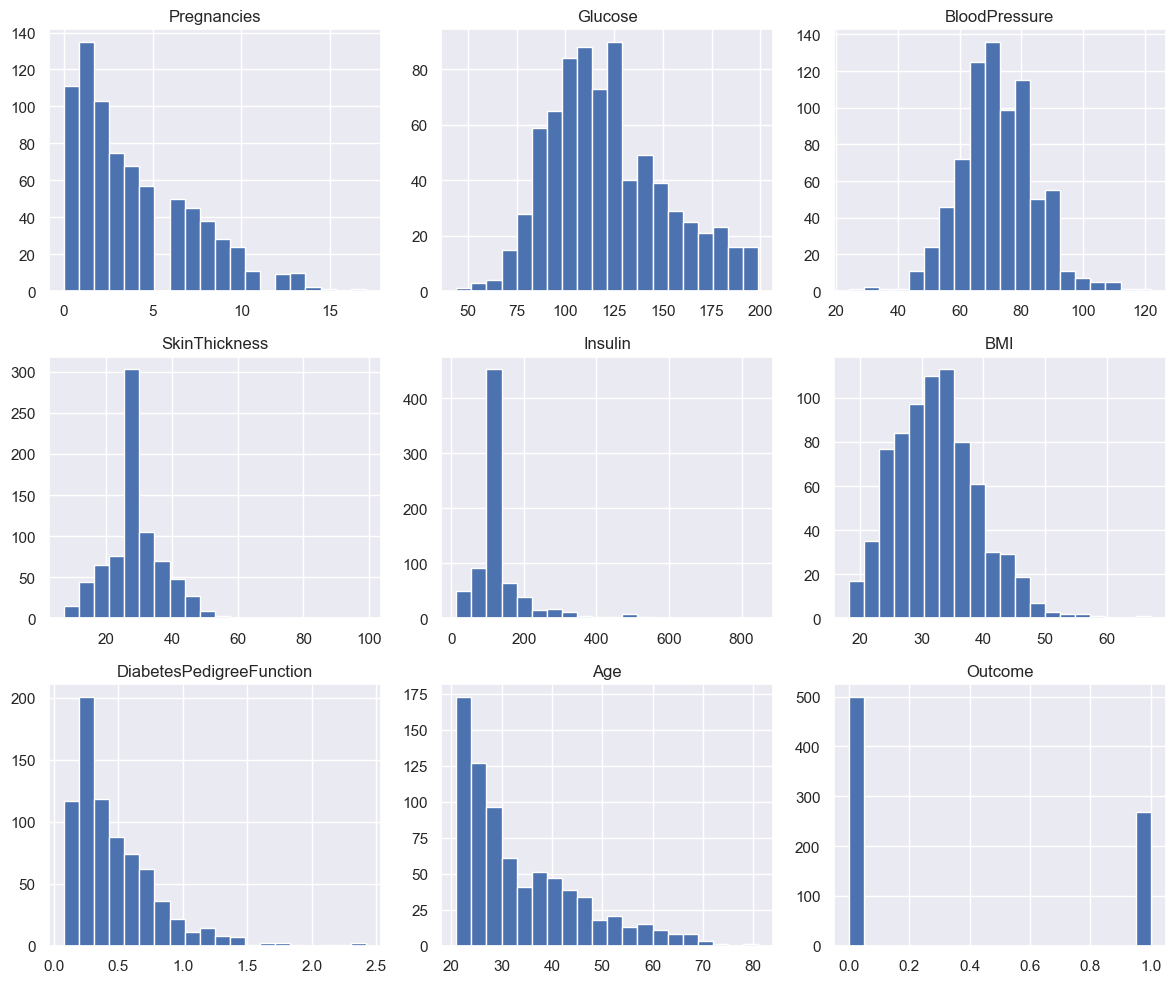

In [8]:
# Plot histograms after replacing missing values
diabetes_data.hist(figsize=(12, 10), bins=20)

plt.tight_layout()
plt.show()

#### Plot the correlation matrix heatmap

Correlation between various features


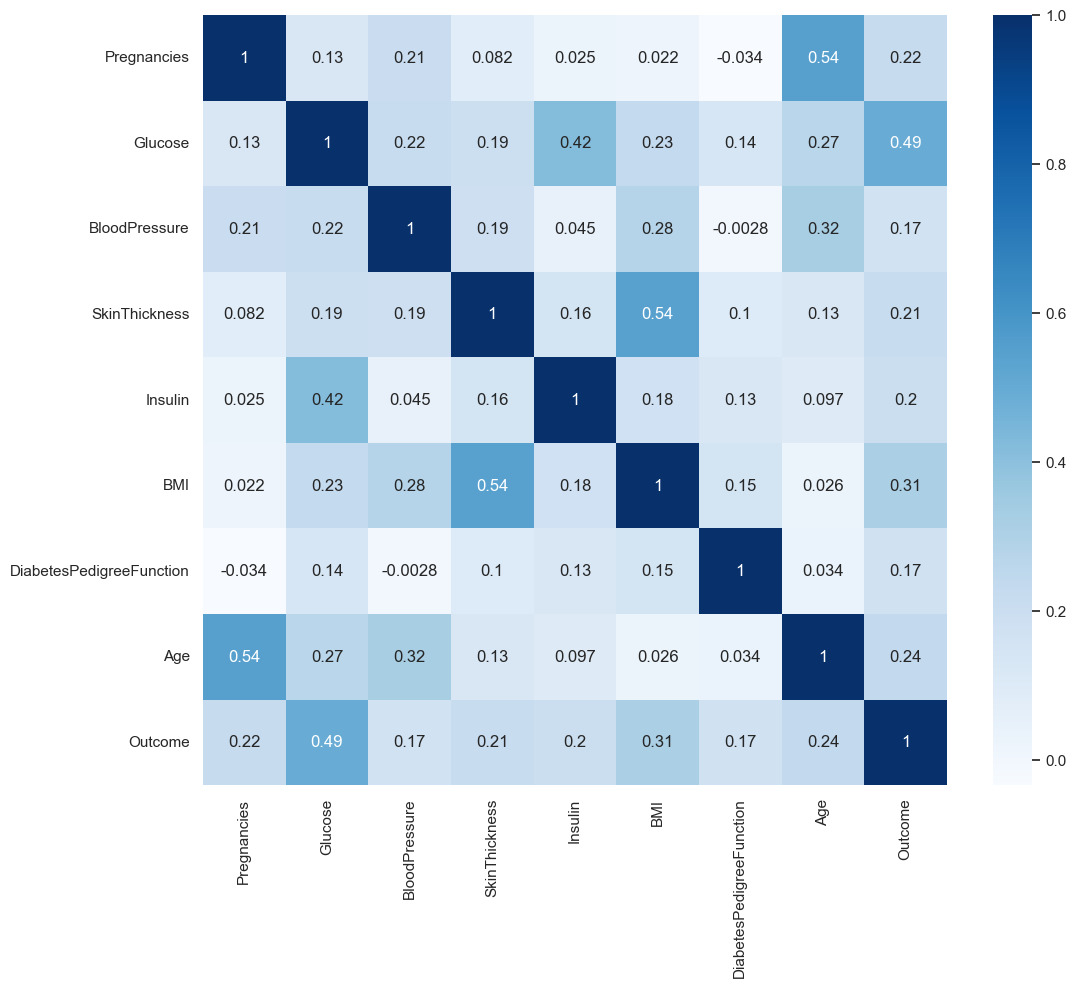

In [9]:
plt.figure(figsize=(12,10))
print('Correlation between various features')
p=sns.heatmap(diabetes_data.corr(), annot=True,cmap ='Blues')

**<font color='teal'> Define the `y` variable as the `Outcome` column.</font>**

In [10]:
# Define X as the predictor features, excluding the target column
X = diabetes_data.drop('Outcome', axis=1)

# Define y as the target variable
y = diabetes_data['Outcome']

**<font color='teal'> Create a 70/30 train and test split. </font>**

In [11]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Check the shapes of the datasets
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (537, 8)
X_test: (231, 8)
y_train: (537,)
y_test: (231,)


**<font color='teal'> Using Sklearn, standarize the magnitude of the features by scaling the values. </font>**

Note: Don't forget to fit() your scaler on X_train and then use that fitted scaler to transform() X_test. This is to avoid data leakage while you standardize your data.

In [12]:
# Create the StandardScaler object
scaler = StandardScaler()

# Fit the scaler on training data and transform the training features
X_train = scaler.fit_transform(X_train)

# Use the same fitted scaler to transform the testing features
X_test = scaler.transform(X_test)

#### Using a range of neighbor values of 1-10, apply the KNearestNeighbor classifier to classify the the data.

In [13]:
from sklearn.neighbors import KNeighborsClassifier

# Create empty lists to store accuracy scores
test_scores = []
train_scores = []

# Test K values from 1 to 10
for i in range(1, 11):

    # Create KNN classifier
    knn = KNeighborsClassifier(n_neighbors=i)

    # Fit the model using training data
    knn.fit(X_train, y_train)

    # Calculate training and testing accuracy
    train_scores.append(knn.score(X_train, y_train))
    test_scores.append(knn.score(X_test, y_test))

**<font color='teal'> Print the train and test scores for each iteration.</font>**

In [14]:
# Print accuracy for each number of neighbors
for i in range(10):
    print(f"K = {i + 1}: Train Score = {train_scores[i]:.4f}, Test Score = {test_scores[i]:.4f}")

K = 1: Train Score = 1.0000, Test Score = 0.7186
K = 2: Train Score = 0.8436, Test Score = 0.7229
K = 3: Train Score = 0.8622, Test Score = 0.7403
K = 4: Train Score = 0.8287, Test Score = 0.7403
K = 5: Train Score = 0.8343, Test Score = 0.7446
K = 6: Train Score = 0.8101, Test Score = 0.7403
K = 7: Train Score = 0.8063, Test Score = 0.7359
K = 8: Train Score = 0.8063, Test Score = 0.7489
K = 9: Train Score = 0.8007, Test Score = 0.7446
K = 10: Train Score = 0.8101, Test Score = 0.7359


**<font color='teal'> Identify the number of neighbors that resulted in the max score in the training dataset. </font>**

In [15]:
# Find the maximum training accuracy
max_train_score = max(train_scores)

# Find the number of neighbors that produced the maximum training accuracy
best_train_k = train_scores.index(max_train_score) + 1

print("Maximum Training Score:", max_train_score)
print("Best K for Training Data:", best_train_k)

Maximum Training Score: 1.0
Best K for Training Data: 1


**<font color='teal'> Identify the number of neighbors that resulted in the max score in the testing dataset. </font>**

In [16]:
# Find the maximum testing accuracy
max_test_score = max(test_scores)

# Find the number of neighbors that produced the maximum testing accuracy
best_test_k = test_scores.index(max_test_score) + 1

print("Maximum Testing Score:", max_test_score)
print("Best K for Testing Data:", best_test_k)

Maximum Testing Score: 0.7489177489177489
Best K for Testing Data: 8


Plot the train and test model performance by number of neighbors.

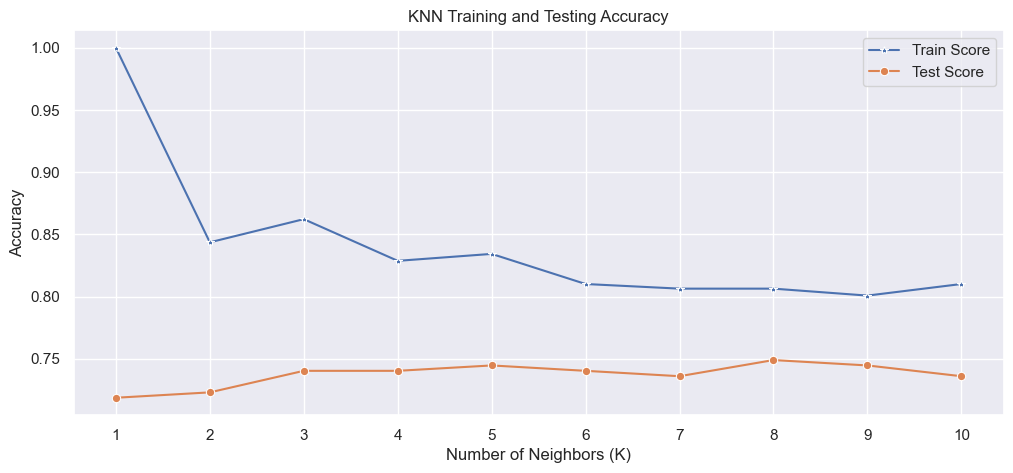

In [17]:
# Plot training and testing accuracy for each number of neighbors
plt.figure(figsize=(12, 5))

# Plot training accuracy
p = sns.lineplot(x=range(1, 11), y=train_scores, marker='*', label='Train Score')

# Plot testing accuracy
p = sns.lineplot(x=range(1, 11), y=test_scores, marker='o', label='Test Score')

plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.title('KNN Training and Testing Accuracy')
plt.xticks(range(1, 11))
plt.legend()
plt.show()

**<font color='teal'> Fit and score the best number of neighbors based on the plot. </font>**

In [18]:
# Identify the K value with the highest testing accuracy
best_k = best_test_k

# Create and train the KNN model using the best K
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

# Calculate training and testing accuracy
print("Best K:", best_k)
print("Training Accuracy:", knn.score(X_train, y_train))
print("Testing Accuracy:", knn.score(X_test, y_test))

Best K: 8
Training Accuracy: 0.8063314711359404
Testing Accuracy: 0.7489177489177489


In [19]:
from sklearn.metrics import confusion_matrix
y_pred = knn.predict(X_test)
pl = confusion_matrix(y_test,y_pred)

**<font color='teal'> Plot the confusion matrix for the model fit above. </font>**

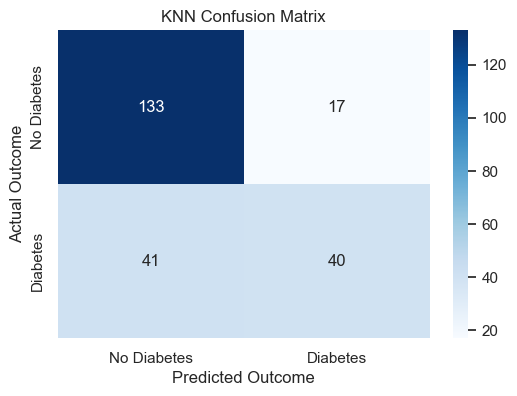

In [20]:
# Plot the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(pl, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])

plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')
plt.title('KNN Confusion Matrix')
plt.show()

**<font color='teal'> Print the classification report </font>**

In [21]:
from sklearn.metrics import classification_report

# Display precision, recall, F1-score, and support
print(classification_report(y_test, y_pred,
                            target_names=['No Diabetes', 'Diabetes']))

              precision    recall  f1-score   support

 No Diabetes       0.76      0.89      0.82       150
    Diabetes       0.70      0.49      0.58        81

    accuracy                           0.75       231
   macro avg       0.73      0.69      0.70       231
weighted avg       0.74      0.75      0.74       231



#### In the case of the K nearest neighbors algorithm, the K parameter is one of the most important parameters affecting the model performance.  The model performance isn't horrible, but what if we didn't consider a wide enough range of values in our neighbors for the KNN? An alternative to fitting a loop of models is to use a grid search to identify the proper number. It is common practice to use a grid search method for all adjustable parameters in any type of machine learning algorithm. First, you define the grid — aka the range of values — to test in the parameter being optimized, and then compare the model outcome performance based on the different values in the grid.

#### Run the code in the next cell to see how to implement the grid search method for identifying the best parameter value for the n_neighbors parameter. Notice the param_grid is the range value to test and we apply cross validation with five folds to score each possible value of n_neighbors.

In [22]:
from sklearn.model_selection import GridSearchCV

# Define the range of neighbor values to test
param_grid = {'n_neighbors': np.arange(1, 50)}

# Create the KNN classifier
knn = KNeighborsClassifier()

# Set up GridSearchCV using five-fold cross-validation
knn_cv = GridSearchCV(knn, param_grid, cv=5)

# Fit GridSearchCV using training data only
knn_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': array([ 1, 2..., 47, 48, 49])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitti

#### Print the best score and best parameter for n_neighbors.

In [23]:
# Print the best cross-validation accuracy
print("Best Score:" + str(knn_cv.best_score_))

# Print the best hyperparameter
print("Best Parameters: " + str(knn_cv.best_params_))

Best Score:0.7561266874350987
Best Parameters: {'n_neighbors': np.int64(9)}


Here you can see that the ideal number of n_neighbors for this model is 14 based on the grid search performed.

Note: In this implementation, GridSearchCV identified 9 as the optimal number of neighbors based on the tested parameter values, with a cross-validation accuracy of approximately 75.61%.

**<font color='teal'> Now, following the KNN example, apply this grid search method to find the optimal number of estimators in a Randon Forest model.
</font>**

In [24]:
# Import libraries
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Create a Random Forest classifier
rf = RandomForestClassifier(random_state=42)

# Define the parameter grid
param_grid = {
    'n_estimators': [10, 20, 30, 40, 50, 100]
}

# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy'
)

# Fit the grid search using training data
grid_search.fit(X_train, y_train)

# Print the best parameter and cross-validation accuracy
print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

Best Parameters: {'n_estimators': 40}
Best CV Accuracy: 0.7635687088958116


In [25]:
# Get the best Random Forest model
best_rf = grid_search.best_estimator_

# Calculate training and testing accuracy
train_score = best_rf.score(X_train, y_train)
test_score = best_rf.score(X_test, y_test)

# Print training and testing accuracy
print(f"Training Accuracy: {train_score:.4f}")
print(f"Testing Accuracy: {test_score:.4f}")

Training Accuracy: 0.9963
Testing Accuracy: 0.7532


### Conclusion

GridSearchCV was used to identify the optimal number of estimators for the Random Forest classifier. Among the tested values, 40 estimators achieved the highest cross-validation accuracy of approximately 76.36% using 5-fold cross-validation. The best model achieved 99.63% training accuracy and 75.32% testing accuracy. The difference between the training and testing results suggests potential overfitting, indicating that the model performs better on the training data than on unseen data. This exercise demonstrates how hyperparameter tuning can help identify suitable model parameters and evaluate model performance.